In [2]:
from pathlib import Path
import sys

# Make the project root importable from notebooks/
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import welch
from src.preprocessing import load_dataset

sns.set_theme(style="whitegrid", context="notebook")

X, y, groups, channel_names = load_dataset()

print("EEG shape:", X.shape)
print("Labels shape:", y.shape)
print("Groups shape:", groups.shape)
print("Unique labels:", np.unique(y))
print("Subjects:", np.unique(groups))
print("Number of channels:", len(channel_names))
print("Channels:", channel_names)


Loading subject 1
Subject 1: 45 trials

Loading subject 2
Subject 2: 45 trials

Loading subject 3
Subject 3: 45 trials

Loading subject 4
Subject 4: 45 trials

Loading subject 5
Subject 5: 45 trials

Loading subject 6
Subject 6: 45 trials

Loading subject 7
Subject 7: 45 trials

Loading subject 8
Subject 8: 45 trials

Loading subject 9
Subject 9: 45 trials

Loading subject 10
Subject 10: 45 trials
EEG shape: (450, 64, 481)
Labels shape: (450,)
Groups shape: (450,)
Unique labels: [0 1]
Subjects: [ 1  2  3  4  5  6  7  8  9 10]
Number of channels: 64
Channels: ['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']


In [3]:
sampling_rate = 160

n_trials, n_channels, n_samples = X.shape
epoch_duration = n_samples / sampling_rate

print(f"Trials: {n_trials}")
print(f"Subjects: {len(np.unique(groups))}")
print(f"Channels: {n_channels}")
print(f"Samples per trial: {n_samples}")
print(f"Nominal epoch duration: {epoch_duration:.3f} s")
print(f"Sampling rate: {sampling_rate} Hz")
print(f"NaN values: {np.isnan(X).sum()}")
print(f"Infinite values: {np.isinf(X).sum()}")

print("\nClass mapping:")
print("0 = left-hand imagery")
print("1 = right-hand imagery")

Trials: 450
Subjects: 10
Channels: 64
Samples per trial: 481
Nominal epoch duration: 3.006 s
Sampling rate: 160 Hz
NaN values: 0
Infinite values: 0

Class mapping:
0 = left-hand imagery
1 = right-hand imagery


,Left imagery,Right imagery
Subject,,
1,23,22
2,23,22
3,23,22
4,23,22
5,21,24
6,24,21
7,23,22
8,22,23
9,24,21


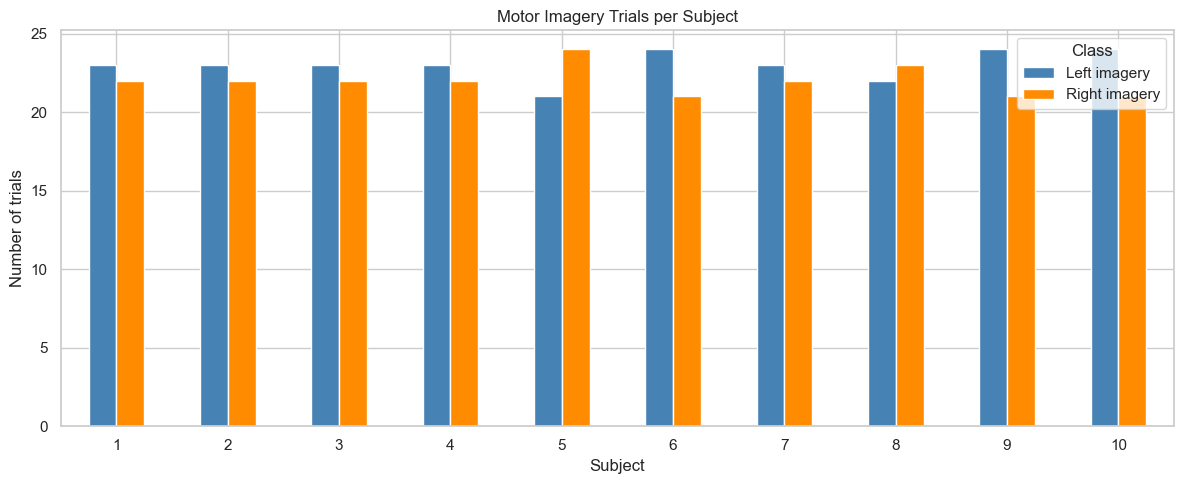

In [4]:
trial_table = pd.crosstab(
    pd.Series(groups, name="Subject"),
    pd.Series(y, name="Class"),
).reindex(columns=[0, 1], fill_value=0)

trial_table.columns = ["Left imagery", "Right imagery"]

display(trial_table)

trial_table.plot(
    kind="bar",
    figsize=(12, 5),
    color=["steelblue", "darkorange"],
)

plt.title("Motor Imagery Trials per Subject")
plt.ylabel("Number of trials")
plt.xlabel("Subject")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

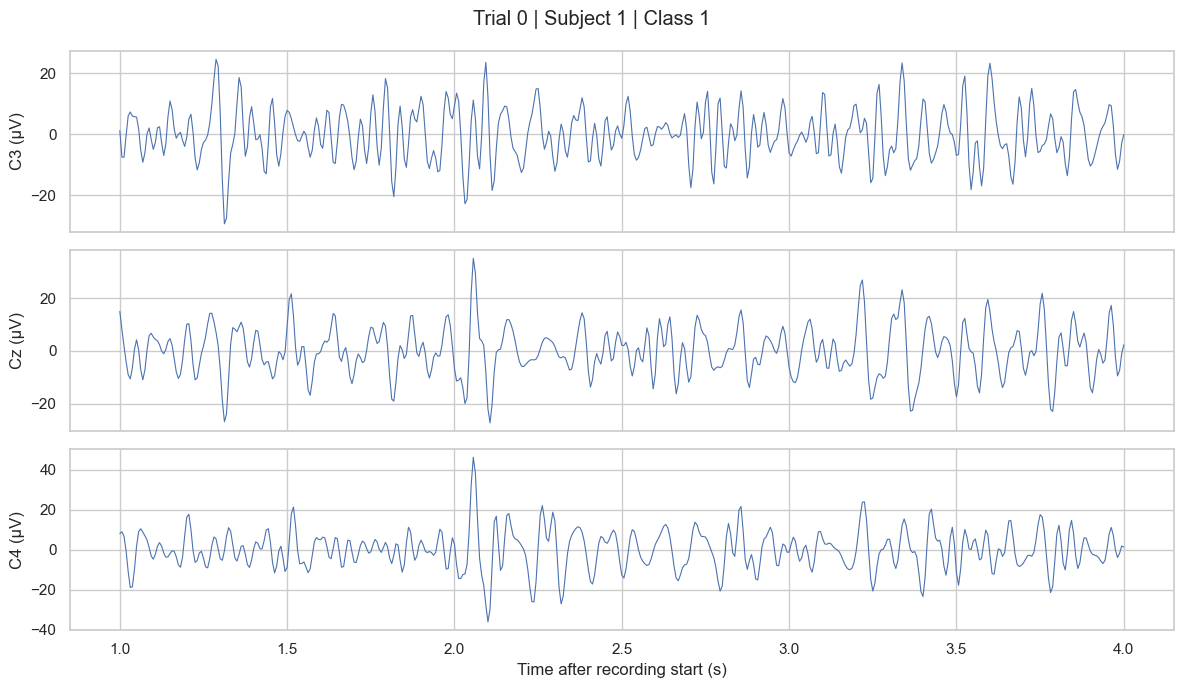

In [5]:
trial_idx = 0
selected_channels = ["C3", "Cz", "C4"]

time = np.arange(n_samples) / sampling_rate + 1.0

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 7),
    sharex=True,
)

for ax, channel in zip(axes, selected_channels):
    ch_idx = channel_names.index(channel)

    # MNE returns EEG in volts by default
    signal_uv = X[trial_idx, ch_idx] * 1e6

    ax.plot(time, signal_uv, linewidth=0.8)
    ax.set_ylabel(f"{channel} (µV)")

axes[-1].set_xlabel("Time after recording start (s)")
fig.suptitle(
    f"Trial {trial_idx} | "
    f"Subject {groups[trial_idx]} | "
    f"Class {y[trial_idx]}"
)
plt.tight_layout()
plt.show()

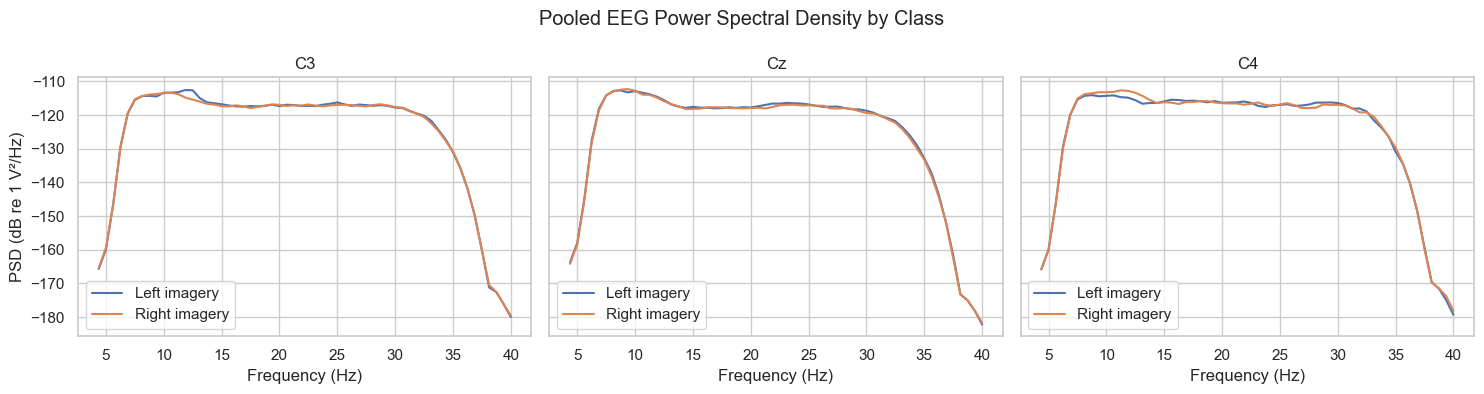

In [6]:
selected_channels = ["C3", "Cz", "C4"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    sharey=True,
)

for ax, channel in zip(axes, selected_channels):
    ch_idx = channel_names.index(channel)

    for label, label_name in [
        (0, "Left imagery"),
        (1, "Right imagery"),
    ]:
        trial_indices = np.where(y == label)[0]
        spectra = []

        for idx in trial_indices:
            freqs, psd = welch(
                X[idx, ch_idx],
                fs=sampling_rate,
                nperseg=256,
            )
            spectra.append(psd)

        mean_psd = np.mean(spectra, axis=0)
        band = (freqs >= 4) & (freqs <= 40)

        ax.plot(
            freqs[band],
            10 * np.log10(mean_psd[band] + 1e-20),
            label=label_name,
        )

    ax.set_title(channel)
    ax.set_xlabel("Frequency (Hz)")
    ax.legend()

axes[0].set_ylabel("PSD (dB re 1 V²/Hz)")
fig.suptitle("Pooled EEG Power Spectral Density by Class")
plt.tight_layout()
plt.show()